# Exploratory Data Analysis - RAG Document Q&A monitoring dataset

**Goal.** Understand the retrieval/answer-quality log (`data/dataset.csv`, 5,000 rows) that accompanies the RAG-based Document Q&A system, check its quality, and relate it to the *measured* behaviour of the actual pipeline (`reports/eval_detail_tfidf.csv`).

**Provenance - please read.** The first 500 rows were supplied with the project brief; rows 501-5,000 were generated synthetically with the same schema and value ranges, and 3.1 % of rows were deliberately injected as faults (retrieval failure, hallucination suspect, truncated chunk). Scores in the original columns are therefore **not measurements of a real system**: relationships between them (or the lack of them) describe how the data was built. Section 8 uses real pipeline measurements instead.

In [1]:
import json
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid", context="notebook")
DATA = Path("..") / "data"; REP = Path("..") / "reports"; FIG = REP / "figures"; FIG.mkdir(exist_ok=True, parents=True)
raw = pd.read_csv(DATA / "dataset_raw.csv")
df = pd.read_csv(DATA / "dataset.csv")
print("raw :", raw.shape, "| cleaned:", df.shape)
df.head()

raw : (5000, 7) | cleaned: (5000, 14)


,doc_id,doc_type,chunk_id,word_count,retrieval_score,query_type,answer_quality_score,category,doc_type_original,anomaly_flag,anomaly_type,chunk_length_band,retrieval_band,quality_band
0,DOC002,Markdown,CHK00001,457,0.5962,analytical,0.942,Constitution,TXT,0,none,long,low,good
1,DOC034,TXT,CHK00002,302,0.7397,factual,0.976,Government Scheme,TXT,0,none,long,medium,good
2,DOC013,Markdown,CHK00003,52,0.7735,comparative,0.660,Constitution,HTML,0,none,short,medium,fair
3,DOC010,HTML,CHK00004,130,0.6278,comparative,0.910,Constitution,Markdown,0,none,medium,medium,good
4,DOC025,TXT,CHK00005,220,0.7817,procedural,0.709,Government Scheme,Word,0,none,medium,medium,fair


## 1. Data quality and cleaning

In [2]:
print(json.dumps(json.load(open(DATA / "cleaning_report.json")), indent=1)[:900])
print("\nNulls in raw:", int(raw.isna().sum().sum()), "| duplicate chunk_ids:", int(raw.chunk_id.duplicated().sum()))
print("dtypes:\n", df.dtypes.astype(str).to_string())

{
 "rows_in": 5000,
 "nulls_before": 0,
 "duplicate_chunk_ids_dropped": 0,
 "invalid_rows_dropped": 0,
 "doc_type_values_changed": 3702,
 "anomalies": {
  "none": 4843,
  "hallucination_suspect": 64,
  "retrieval_failure": 60,
  "truncated_chunk": 33
 },
 "anomaly_rate": 0.0314,
 "rule_flags_match_label_file": true,
 "rows_out": 5000,
 "columns_out": [
  "doc_id",
  "doc_type",
  "chunk_id",
  "word_count",
  "retrieval_score",
  "query_type",
  "answer_quality_score",
  "category",
  "doc_type_original",
  "anomaly_flag",
  "anomaly_type",
  "chunk_length_band",
  "retrieval_band",
  "quality_band"
 ]
}

Nulls in raw: 0 | duplicate chunk_ids: 0
dtypes:
 doc_id                      str
doc_type                    str
chunk_id                    str
word_count                int64
retrieval_score         float64
query_type                  str
answer_quality_score    float64
category                    str
doc_type_original           str
anomaly_flag              int64
anomaly_type     

In [3]:
# The raw data lists 3-5 different doc_type values for the SAME document - not physically possible.
inconsistent = raw.groupby("doc_id").doc_type.nunique()
print("formats per doc_id in raw  : min %d, median %d, max %d" % (inconsistent.min(), inconsistent.median(), inconsistent.max()))
print("formats per doc_id cleaned :", df.groupby("doc_id").doc_type.nunique().max())
print("rows whose doc_type changed:", int((df.doc_type != df.doc_type_original).sum()), "of", len(df))

formats per doc_id in raw  : min 5, median 5, max 5
formats per doc_id cleaned : 1
rows whose doc_type changed: 3702 of 5000


## 2. Summary statistics

In [4]:
num = ["word_count", "retrieval_score", "answer_quality_score"]
df[num].describe().round(3)

,word_count,retrieval_score,answer_quality_score
count,5000.000,5000.000,5000.000
mean,270.776,0.745,0.787
std,133.594,0.154,0.138
min,5.000,0.050,0.155
25%,154.000,0.622,0.690
50%,266.000,0.751,0.798
75%,390.250,0.874,0.896
max,499.000,1.000,1.000


In [5]:
for c in ["doc_type", "query_type", "category", "anomaly_type"]:
    print(df[c].value_counts(normalize=True).round(3).to_frame("share").T.to_string(), "\n")

doc_type  Markdown    PDF    TXT  Word   HTML
share        0.538  0.169  0.155  0.08  0.058 

query_type  summarization  procedural  factual  comparative  analytical
share               0.241       0.216    0.188        0.181       0.173 

category  Constitution  Government Scheme  Technical Manual
share            0.396              0.313             0.291 

anomaly_type   none  hallucination_suspect  retrieval_failure  truncated_chunk
share         0.969                  0.013              0.012            0.007 



## 3. Visualisation 1 - distributions of the two scores

             retrieval_score              answer_quality_score              
                        mean   min    max                 mean    min    max
anomaly_flag                                                                
0                      0.750  0.50  1.000                0.800  0.600  1.000
1                      0.618  0.05  0.994                0.367  0.155  0.599


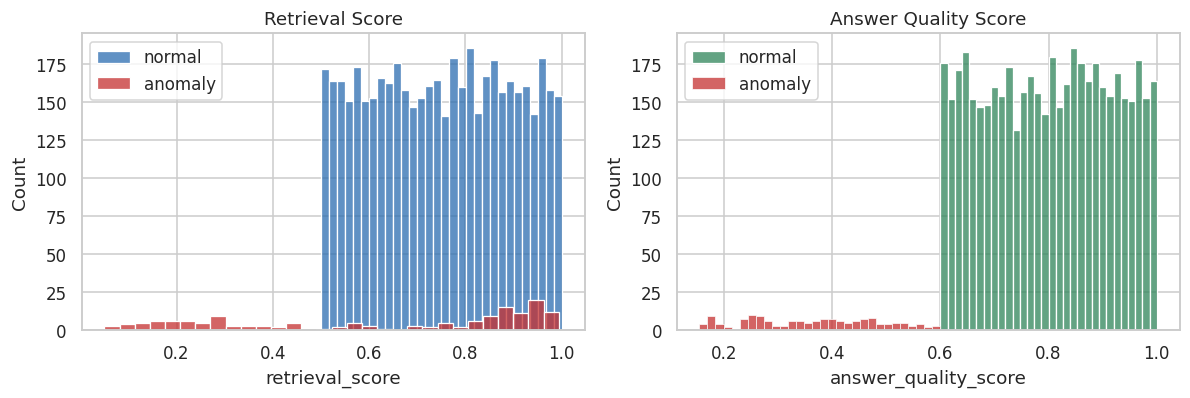

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for a, col, c in zip(ax, ["retrieval_score", "answer_quality_score"], ["#2b6cb0", "#2f855a"]):
    sns.histplot(df[df.anomaly_flag == 0][col], bins=30, color=c, ax=a, label="normal")
    sns.histplot(df[df.anomaly_flag == 1][col], bins=30, color="#c53030", ax=a, label="anomaly")
    a.set_title(col.replace("_", " ").title()); a.legend()
plt.tight_layout(); plt.savefig(FIG / "eda_distributions.png", dpi=150); plt.show()
print(df.groupby("anomaly_flag")[["retrieval_score","answer_quality_score"]].agg(["mean","min","max"]).round(3).to_string())

**Reading.** Normal rows are close to uniform within the documented ranges (retrieval 0.50-1.00, quality 0.60-1.00). Anomalies fall *outside* those ranges - low retrieval, or low quality - which is what makes them detectable with simple rules.

## 4. Visualisation 2 - chunk length

Kruskal-Wallis word_count ~ doc_type: H=1.15 p=0.886


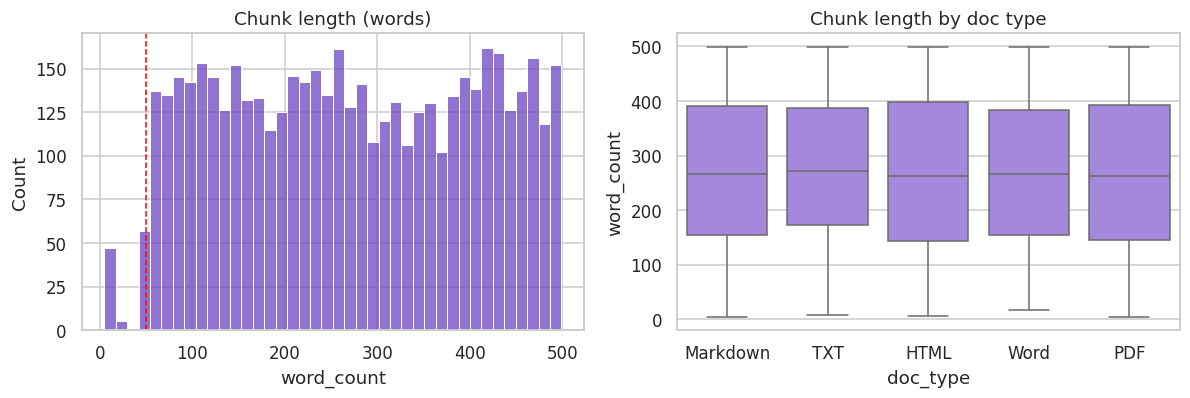

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
sns.histplot(df.word_count, bins=40, ax=ax[0], color="#6b46c1"); ax[0].set_title("Chunk length (words)"); ax[0].axvline(50, color="red", ls="--", lw=1)
sns.boxplot(data=df, x="doc_type", y="word_count", ax=ax[1], color="#9f7aea"); ax[1].set_title("Chunk length by doc type")
plt.tight_layout(); plt.savefig(FIG / "eda_wordcount.png", dpi=150); plt.show()
k = stats.kruskal(*[g.word_count.values for _, g in df.groupby("doc_type")])
print("Kruskal-Wallis word_count ~ doc_type: H=%.2f p=%.3f" % k)

## 5. Visualisation 3 - query type vs answer quality

Kruskal-Wallis quality ~ query_type: H=4.44, p=0.350 -> no significant difference


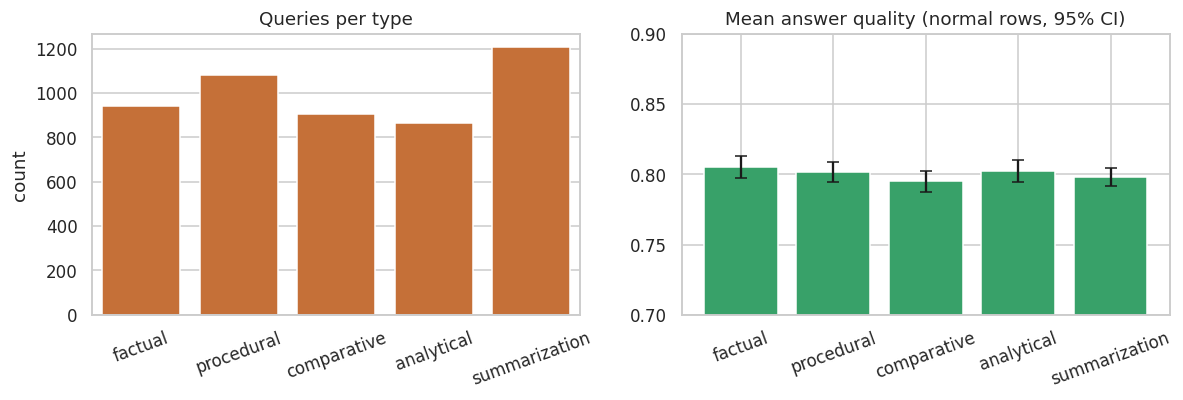

In [8]:
order = ["factual", "procedural", "comparative", "analytical", "summarization"]
g = df[df.anomaly_flag == 0].groupby("query_type").answer_quality_score.agg(["mean", "std", "count"]).loc[order]
g["ci95"] = 1.96 * g["std"] / np.sqrt(g["count"])
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
sns.countplot(data=df, x="query_type", order=order, ax=ax[0], color="#dd6b20"); ax[0].set_title("Queries per type")
ax[1].bar(order, g["mean"], yerr=g["ci95"], color="#38a169", capsize=4); ax[1].set_ylim(0.7, 0.9)
ax[1].set_title("Mean answer quality (normal rows, 95% CI)")
plt.setp(ax, xlabel=""); [t.set_rotation(20) for a in ax for t in a.get_xticklabels()]
plt.tight_layout(); plt.savefig(FIG / "eda_query_type.png", dpi=150); plt.show()
H, p = stats.kruskal(*[x.answer_quality_score.values for _, x in df[df.anomaly_flag == 0].groupby("query_type")])
print("Kruskal-Wallis quality ~ query_type: H=%.2f, p=%.3f -> %s" % (H, p, "no significant difference" if p > .05 else "significant difference"))

## 6. Visualisation 4 and 5 - retrieval vs quality, correlations

Spearman retrieval~quality: all rows rho=-0.003 | normal rows rho=-0.016 (p=0.26)


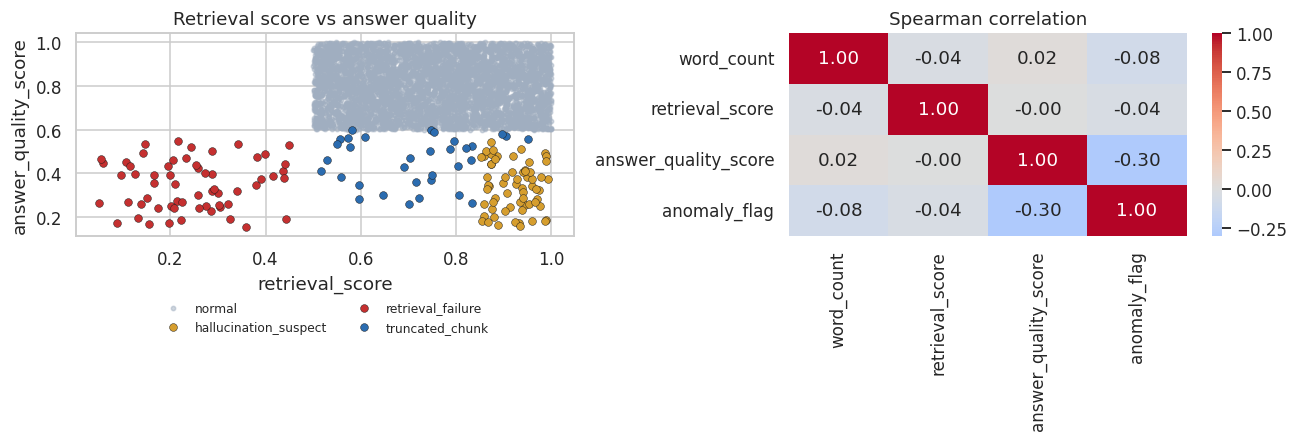

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
pal = {"none": "#a0aec0", "retrieval_failure": "#c53030", "hallucination_suspect": "#d69e2e", "truncated_chunk": "#2b6cb0"}
norm = df[df.anomaly_flag == 0]; an = df[df.anomaly_flag == 1]
ax[0].scatter(norm.retrieval_score, norm.answer_quality_score, s=8, c=pal["none"], alpha=.5, label="normal")
for t, grp in an.groupby("anomaly_type"):
    ax[0].scatter(grp.retrieval_score, grp.answer_quality_score, s=26, c=pal[t], edgecolor="k", lw=.3, label=t)
ax[0].set_xlabel("retrieval_score"); ax[0].set_ylabel("answer_quality_score"); ax[0].set_title("Retrieval score vs answer quality")
ax[0].legend(loc="upper center", bbox_to_anchor=(0.5, -0.27), ncol=2, fontsize=8, frameon=False)
corr = df[num + ["anomaly_flag"]].corr(method="spearman")
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax[1]); ax[1].set_title("Spearman correlation")
plt.tight_layout(); plt.savefig(FIG / "eda_scatter_corr.png", dpi=150); plt.show()
r_all = stats.spearmanr(df.retrieval_score, df.answer_quality_score)
r_norm = stats.spearmanr(*df[df.anomaly_flag == 0][["retrieval_score", "answer_quality_score"]].T.values)
print("Spearman retrieval~quality: all rows rho=%.3f | normal rows rho=%.3f (p=%.2f)" % (r_all.statistic, r_norm.statistic, r_norm.pvalue))

**Reading.** Among normal rows retrieval score and quality are essentially uncorrelated - a property of the synthetic generator, *not* a finding about real RAG systems (where better retrieval normally gives better answers; see Section 8). The anomalies stand out clearly in the scatter plot: low-retrieval failures on the left, and *hallucination suspects* - high retrieval but poor answer - at the bottom-right.

## 7. Visualisation 6 - where are the anomalies?

anomaly_type
none                     4843
hallucination_suspect      64
retrieval_failure          60
truncated_chunk            33
chi-square anomaly ~ category: chi2=0.41 p=0.814


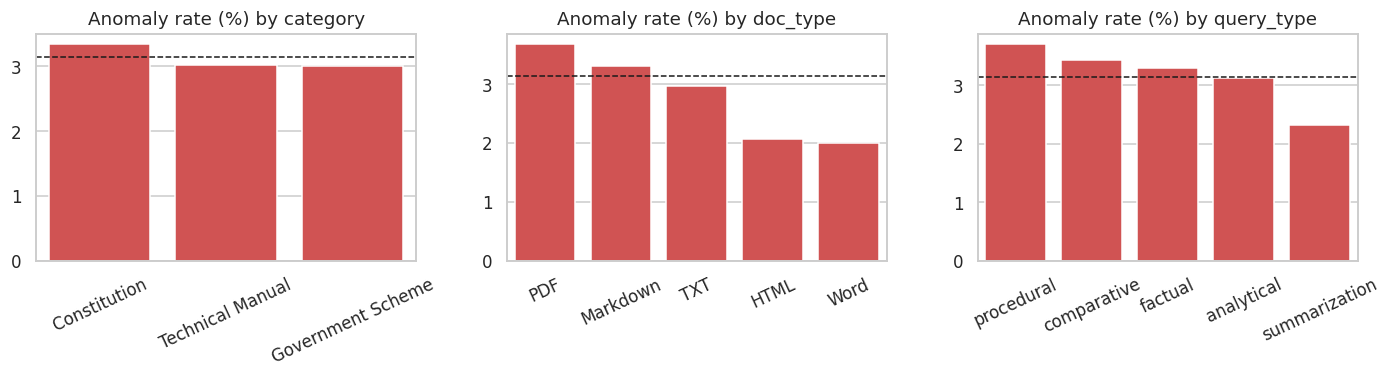

In [10]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
for a, col in zip(ax, ["category", "doc_type", "query_type"]):
    r = df.groupby(col).anomaly_flag.mean().sort_values(ascending=False) * 100
    sns.barplot(x=r.index, y=r.values, ax=a, color="#e53e3e"); a.set_title(f"Anomaly rate (%) by {col}"); a.set_xlabel("")
    a.axhline(df.anomaly_flag.mean() * 100, color="k", ls="--", lw=1); [t.set_rotation(25) for t in a.get_xticklabels()]
plt.tight_layout(); plt.savefig(FIG / "eda_anomaly.png", dpi=150); plt.show()
print(df.anomaly_type.value_counts().to_string())
chi = stats.chi2_contingency(pd.crosstab(df.category, df.anomaly_flag))
print("chi-square anomaly ~ category: chi2=%.2f p=%.3f" % (chi[0], chi[1]))

## 8. Real measurements from the pipeline (not synthetic)

`scripts/evaluate.py` ran the offline TF-IDF baseline on 1,000 questions (150 hand-written *gold*, 850 synthetic cloze) and recorded what was actually retrieved. Note that only a handful of gold questions retrieved the wrong document, so the left-hand box plot rests on very few points.

                     count   mean    std    min    25%    50%    75%    max
retrieved_right_doc                                                        
False                  5.0  0.264  0.119  0.113  0.166  0.295  0.358  0.385
True                 145.0  0.304  0.094  0.096  0.241  0.301  0.372  0.508


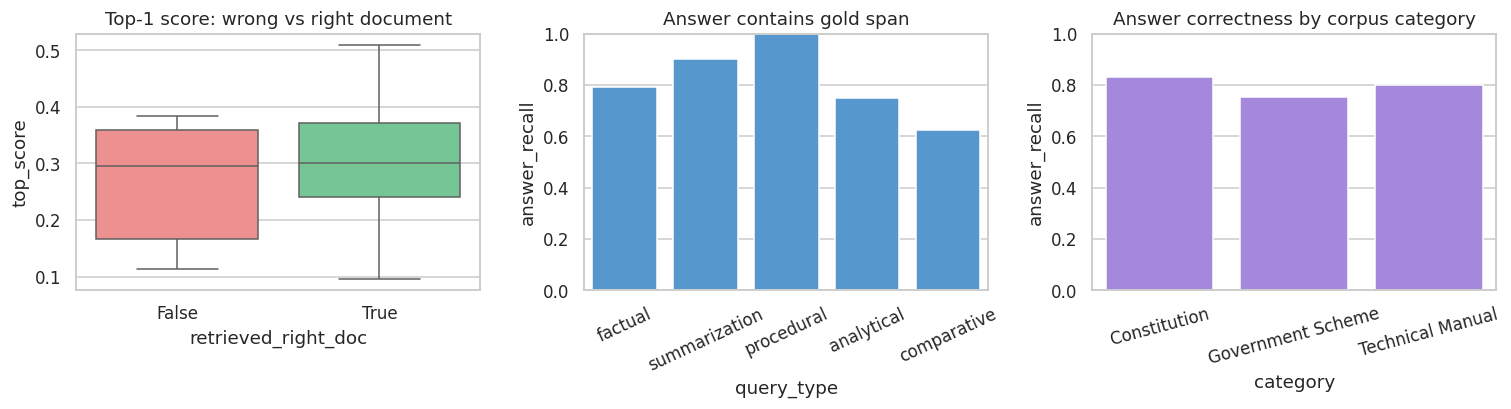

In [11]:
ev = pd.read_csv(REP / "eval_detail_tfidf.csv")
man = pd.read_csv(DATA / "corpus_manifest.csv").set_index("doc_id")
g = ev[ev.origin == "gold"].copy()
g["retrieved_right_doc"] = g.top_doc == g.gold_doc
g["category"] = g.gold_doc.map(man.category)
fig, ax = plt.subplots(1, 3, figsize=(14, 3.9))
sns.boxplot(data=g, x="retrieved_right_doc", y="top_score", hue="retrieved_right_doc", legend=False, ax=ax[0], palette=["#fc8181", "#68d391"]); ax[0].set_title("Top-1 score: wrong vs right document")
sns.barplot(data=g, x="query_type", y=(g.answer_recall >= .8).astype(float), ax=ax[1], color="#4299e1", errorbar=None); ax[1].set_title("Answer contains gold span"); ax[1].set_ylim(0, 1)
[t.set_rotation(25) for t in ax[1].get_xticklabels()]
sns.barplot(data=g, x="category", y=(g.answer_recall >= .8).astype(float), ax=ax[2], color="#9f7aea", errorbar=None); ax[2].set_title("Answer correctness by corpus category"); ax[2].set_ylim(0, 1)
[t.set_rotation(15) for t in ax[2].get_xticklabels()]
plt.tight_layout(); plt.savefig(FIG / "eda_real_eval.png", dpi=150); plt.show()
print(g.groupby("retrieved_right_doc").top_score.describe().round(3).to_string())

In [12]:
# Which synthetic-vs-real difference matters: cloze questions leak the answer's wording and the document title.
res = json.load(open(REP / "eval_results_tfidf.json"))
pd.DataFrame({"gold (hand-written)": res["gold"], "synthetic cloze": res["synthetic_cloze"]}).round(3).loc[["n","doc_hit@1","doc_hit@3","doc_mrr@5","answer_correct_rate","false_abstain_rate"]]

,gold (hand-written),synthetic cloze
n,150.000,850.000
doc_hit@1,0.967,1.000
doc_hit@3,0.993,1.000
doc_mrr@5,0.980,1.000
answer_correct_rate,0.800,0.985
false_abstain_rate,0.067,0.000


## 9. Key findings

In [13]:
n_an = int(df.anomaly_flag.sum())
print(f"1. Quality: {len(df):,} rows, 0 nulls, 0 duplicate chunk_ids; doc_type was inconsistent for every document and was harmonised ({int((df.doc_type != df.doc_type_original).sum()):,} values changed).")
print(f"2. Anomalies: {n_an} rows ({df.anomaly_flag.mean():.1%}) flagged by three simple rules; they are retained and labelled, not dropped.")
print(f"3. In the synthetic log, retrieval score and answer quality are uncorrelated in normal rows (rho={r_norm.statistic:.2f}); this reflects the generator, so it must not be quoted as a property of RAG.")
ab = res["abstention"]
print(f"4. Real pipeline: the top-1 score separates in-scope questions (median {ab['median_top_score_in_scope']:.2f}) from out-of-scope ones (median {ab['median_top_score_out_of_scope']:.2f}); abstaining below {ab['threshold']:.2f} catches {ab['out_of_scope_correctly_abstained']:.0%} of out-of-scope questions at the cost of {ab['in_scope_wrongly_abstained']:.1%} wrongly refused in-scope ones. Only {int((~g.retrieved_right_doc).sum())} gold questions retrieved the wrong document, too few to claim the score predicts retrieval correctness.")
print(f"5. Real pipeline on gold questions: doc hit@1={res['gold']['doc_hit@1']:.1%}, hit@3={res['gold']['doc_hit@3']:.1%}, answer-contains-gold-span={res['gold']['answer_correct_rate']:.1%} (extractive baseline).")
print(f"6. Synthetic cloze questions score {res['synthetic_cloze']['answer_correct_rate']:.1%} answer-correct versus {res['gold']['answer_correct_rate']:.1%} on gold - they are a sanity check, not a benchmark.")

1. Quality: 5,000 rows, 0 nulls, 0 duplicate chunk_ids; doc_type was inconsistent for every document and was harmonised (3,702 values changed).
2. Anomalies: 157 rows (3.1%) flagged by three simple rules; they are retained and labelled, not dropped.
3. In the synthetic log, retrieval score and answer quality are uncorrelated in normal rows (rho=-0.02); this reflects the generator, so it must not be quoted as a property of RAG.
4. Real pipeline: the top-1 score separates in-scope questions (median 0.30) from out-of-scope ones (median 0.09); abstaining below 0.15 catches 77% of out-of-scope questions at the cost of 6.7% wrongly refused in-scope ones. Only 5 gold questions retrieved the wrong document, too few to claim the score predicts retrieval correctness.
5. Real pipeline on gold questions: doc hit@1=96.7%, hit@3=99.3%, answer-contains-gold-span=80.0% (extractive baseline).
6. Synthetic cloze questions score 98.5% answer-correct versus 80.0% on gold - they are a sanity check, not a b